# Univariate analysis

In [1]:
# Imports and project paths
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import seaborn as sns
from src.data.loader import load_phenotypes
from src.config import MORE_EXPRESSED_GENES, L1_REGULATORS, L1_REGULATORS_WITH_2_STEPS_FROM_MECP2
from src.data.loader import load_all_regions
import pandas as pd


In [2]:
# Load the donor phenotypes (sex, age and death classification)
df = load_phenotypes()

## Descrição do conjunto de dados

In [3]:
# Dataset overview: number of brain samples, donors, regions, genes and phenotype variables
headers = load_all_regions(nrows=0)

samples_per_region = pd.Series(
    {region.value: len(expr.columns) - 2 for region, expr in headers.items()}
).sort_values(ascending=False)

brain_samples = [s for expr in headers.values() for s in expr.columns[2:]]
brain_donors = {"-".join(s.split("-")[:2]) for s in brain_samples}

with open(next(iter(headers)).file) as f:
    f.readline()
    n_genes = int(f.readline().split()[0])

summary = pd.Series({
    "Amostras (cérebro)": len(brain_samples),
    "Doadores (cérebro)": len(brain_donors),
    "Regiões do cérebro": len(headers),
    "Genes": n_genes,
    "Doadores no arquivo de fenótipos": len(df),
    "Variáveis de fenótipo": df.shape[1] - 1,
})
summary

Amostras (cérebro)                   3234
Doadores (cérebro)                    393
Regiões do cérebro                     13
Genes                               74628
Doadores no arquivo de fenótipos      981
Variáveis de fenótipo                   3
dtype: int64

In [4]:
# Number and share of samples in each brain region
pd.DataFrame({
    "Amostras": samples_per_region,
    "Proporção (%)": (samples_per_region / samples_per_region.sum() * 100).round(1),
})

,Amostras,Proporção (%)
caudate_basal_ganglia,300,9.3
nucleus_accumbens_basal_ganglia,285,8.8
cerebellar_hemisphere,277,8.6
cortex,270,8.3
frontal_cortex_ba9,269,8.3
cerebellum,266,8.2
hypothalamus,257,7.9
hippocampus,255,7.9
putamen_basal_ganglia,254,7.9
anterior_cingulate_cortex_ba24,233,7.2


In [5]:
# First rows of the phenotype table
df.head(10)

,SUBJID,SEX,AGE,DTHHRDY
0,GTEX-1117F,2,60-69,4.0
1,GTEX-111CU,1,50-59,0.0
2,GTEX-111FC,1,60-69,1.0
3,GTEX-111VG,1,60-69,3.0
4,GTEX-111YS,1,60-69,0.0
5,GTEX-1122O,2,60-69,0.0
6,GTEX-1128S,2,60-69,2.0
7,GTEX-113IC,1,60-69,NaN
8,GTEX-113JC,2,50-59,2.0
9,GTEX-117XS,1,60-69,2.0


In [6]:
# Summary statistics of the phenotype table
df.describe()

,SEX,DTHHRDY
count,981.000000,962.000000
mean,1.333333,1.209979
std,0.471645,1.448234
min,1.000000,0.000000
25%,1.000000,0.000000
50%,1.000000,0.000000
75%,2.000000,2.000000
max,2.000000,4.000000


In [7]:
# Column types and missing values of the phenotype table
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 981 entries, 0 to 980
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SUBJID   981 non-null    str    
 1   SEX      981 non-null    int64  
 2   AGE      981 non-null    str    
 3   DTHHRDY  962 non-null    float64
dtypes: float64(1), int64(1), str(2)
memory usage: 30.8 KB


In [8]:
# Number of donors of each sex in the whole GTEx
df["SEX"].value_counts()

SEX
1    654
2    327
Name: count, dtype: int64

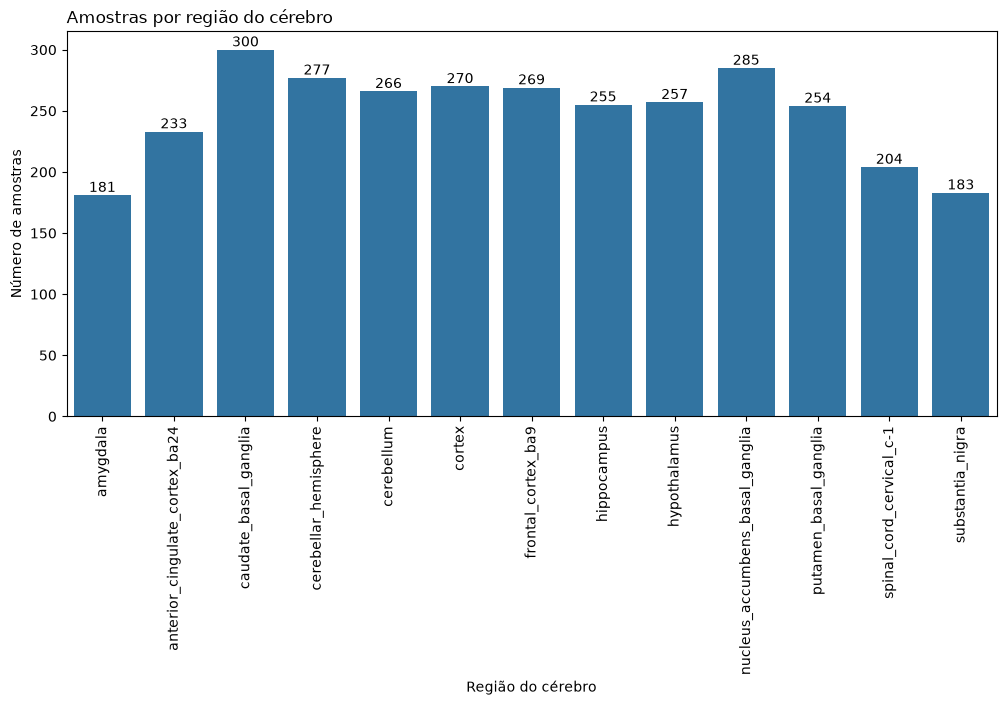

In [9]:
# Bar plot with the number of samples per brain region
samples_per_region = pd.Series({region.value: len(expr.columns) - 2 for region, expr in load_all_regions(nrows=0).items()})

plt.figure(figsize=(12, 5))
ax = sns.barplot(x=samples_per_region.index, y=samples_per_region.values)
ax.bar_label(ax.containers[0])
plt.xticks(rotation=90)
plt.xlabel("Região do cérebro")
plt.ylabel("Número de amostras")
plt.title("Amostras por região do cérebro", loc="left")
plt.show()

Podemos ver que os dados estao distribuidos entre as diferentes regiões do cerebro onde a maior variedade é com a amigdala e o caudado, com 1,7 vezes a diferença.

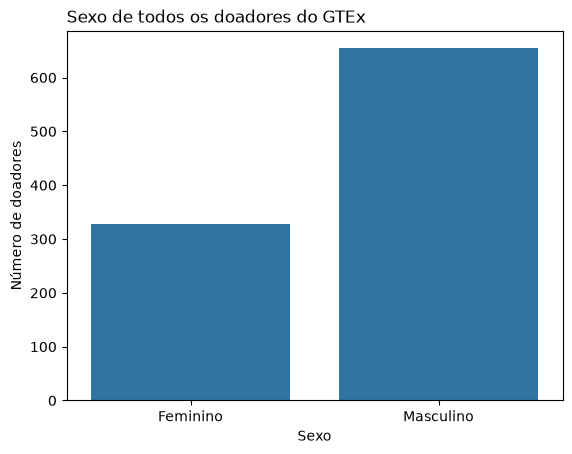

In [10]:
# Sex of all GTEx donors
sns.countplot(x=df["SEX"].replace({1: "Masculino", 2: "Feminino"}))
plt.xlabel("Sexo")
plt.ylabel("Número de doadores")
plt.title("Sexo de todos os doadores do GTEx", loc="left")
plt.show()

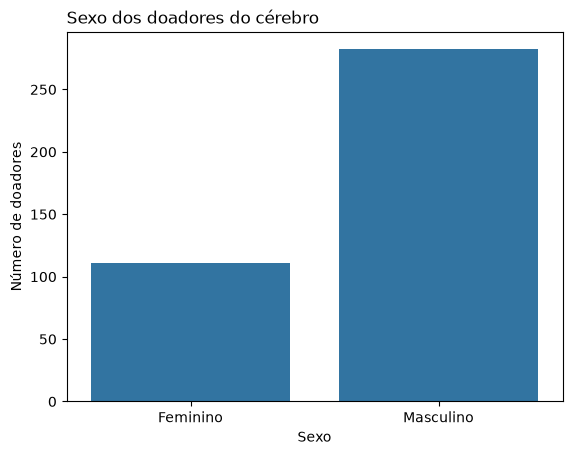

SEX
1    282
2    111
Name: count, dtype: int64

In [11]:
# Keep only the brain donors and plot their sex
brain_donors = {
    "-".join(sample.split("-")[:2])
    for expr in load_all_regions(nrows=0).values()
    for sample in expr.columns[2:]
}
brain_df = df[df["SUBJID"].isin(brain_donors)]

sns.countplot(x=brain_df["SEX"].replace({1: "Masculino", 2: "Feminino"}))
plt.xlabel("Sexo")
plt.ylabel("Número de doadores")
plt.title("Sexo dos doadores do cérebro", loc="left")
plt.show()
brain_df["SEX"].value_counts()

Temos mais que o dobro de amostras vindas de pessoas do sexo masculino, tanto para o descritor de todos os tecidos quanto para os tecidos cerebrais.

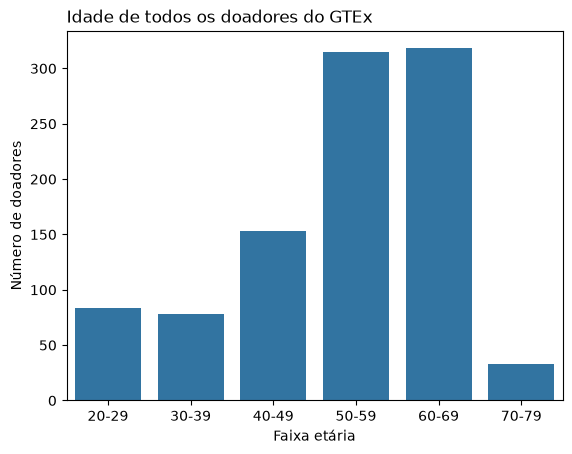

In [12]:
# Age ranges of all GTEx donors
sns.countplot(x=df["AGE"], order=sorted(df["AGE"].unique()))
plt.xlabel("Faixa etária")
plt.ylabel("Número de doadores")
plt.title("Idade de todos os doadores do GTEx", loc="left")
plt.show()

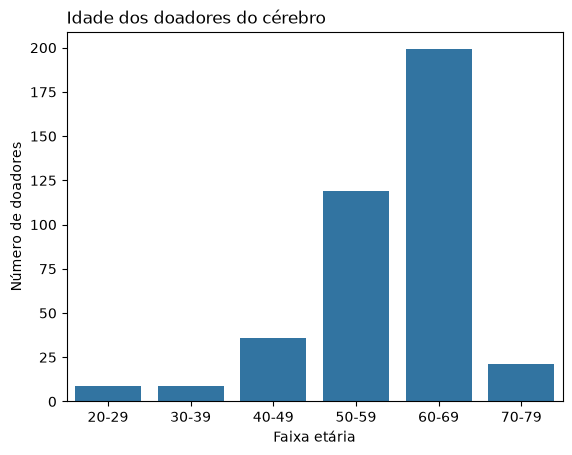

In [13]:
# Age ranges of the brain donors
sns.countplot(x=brain_df["AGE"], order=sorted(df["AGE"].unique()))
plt.xlabel("Faixa etária")
plt.ylabel("Número de doadores")
plt.title("Idade dos doadores do cérebro", loc="left")
plt.show()

Fator importante para a análise os dados que temos se concentra principalmente na faixa etária que é entre 60 - 69 anos. Importante saber disso, pois queremos visualizar como os genes em sexos diferentes variam de expressão ao longo da vida.

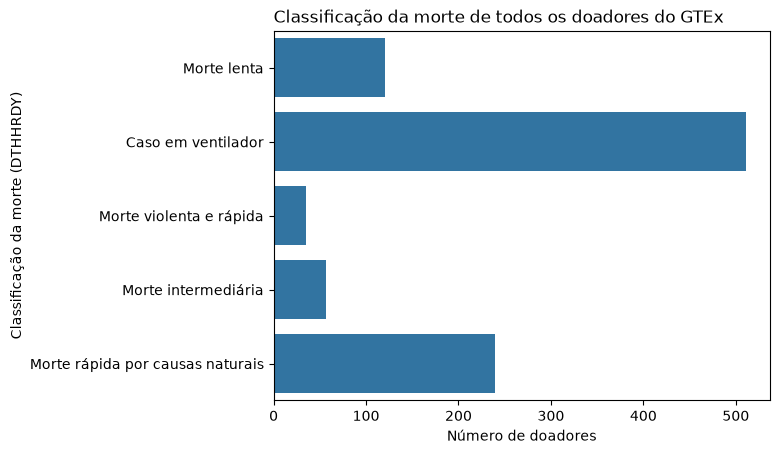

In [14]:
# Death classification (Hardy scale) of all GTEx donors
sns.countplot(y=df["DTHHRDY"].replace({
    0: "Caso em ventilador",
    1: "Morte violenta e rápida",
    2: "Morte rápida por causas naturais",
    3: "Morte intermediária",
    4: "Morte lenta"
}))
plt.xlabel("Número de doadores")
plt.ylabel("Classificação da morte (DTHHRDY)")
plt.title("Classificação da morte de todos os doadores do GTEx", loc="left")
plt.show()

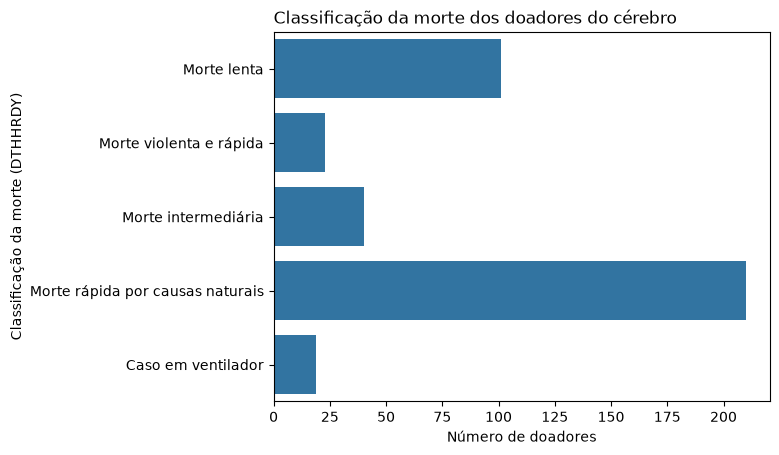

In [15]:
# Death classification (Hardy scale) of the brain donors
sns.countplot(y=brain_df["DTHHRDY"].replace({
    0: "Caso em ventilador",
    1: "Morte violenta e rápida",
    2: "Morte rápida por causas naturais",
    3: "Morte intermediária",
    4: "Morte lenta"
}))
plt.xlabel("Número de doadores")
plt.ylabel("Classificação da morte (DTHHRDY)")
plt.title("Classificação da morte dos doadores do cérebro", loc="left")
plt.show()

Uma grande limitação que temos é um contraste muito grande entre os tipos de causas de morte. Melhores descritos em `src/data/README.md`

In [16]:
# Load the full expression matrices of all brain regions
regions = load_all_regions(nrows=None)

In [17]:
# Long table with the TPM of the selected genes (L1 regulators and most expressed genes) in every region
genes = []
for region, expr in regions.items():
    g = expr[expr["Description"].isin(L1_REGULATORS + MORE_EXPRESSED_GENES)]
    g = g.drop(columns="Name").melt(id_vars="Description", var_name="sample", value_name="TPM")
    g["region"] = region.value
    genes.append(g)

genes = pd.concat(genes)
print(genes.shape)
genes.head()

(352506, 4)


,Description,sample,TPM,region
0,KDM1A,GTEX-1117F-0011-R4b-SM-GI4VM,8.842710,amygdala
1,RUNX3,GTEX-1117F-0011-R4b-SM-GI4VM,0.967832,amygdala
2,PABPC4,GTEX-1117F-0011-R4b-SM-GI4VM,24.448600,amygdala
3,TUT4,GTEX-1117F-0011-R4b-SM-GI4VM,5.511600,amygdala
4,HENMT1,GTEX-1117F-0011-R4b-SM-GI4VM,3.591080,amygdala


In [18]:
# Join all regions into a single genes x samples matrix
expression = pd.concat(
    [expr.set_index(["Name", "Description"]) for expr in regions.values()], axis=1
)
expression.shape

(74628, 3234)

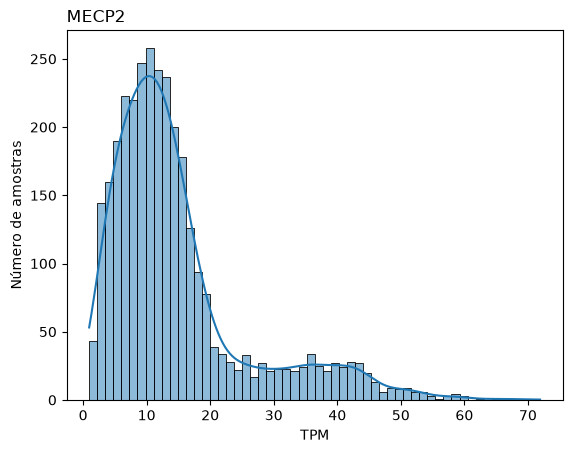

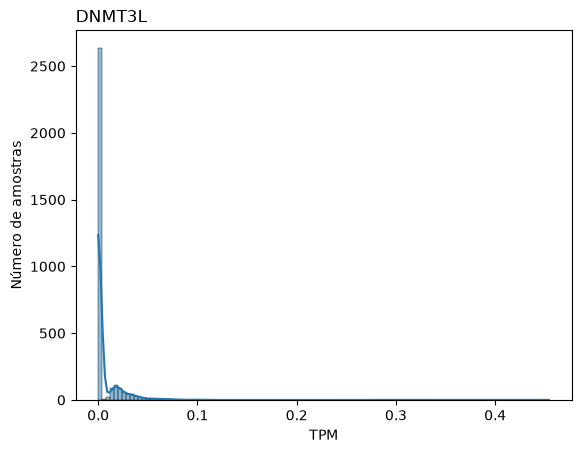

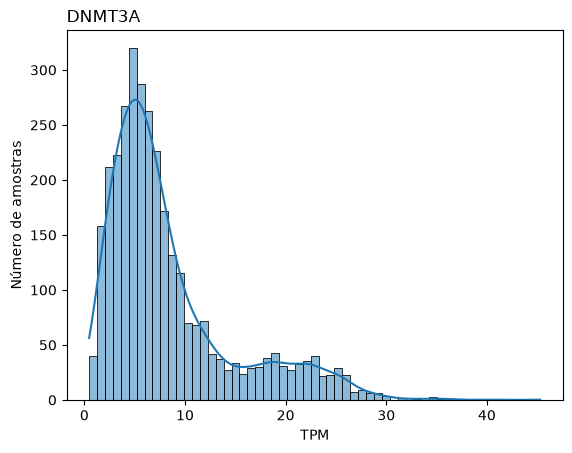

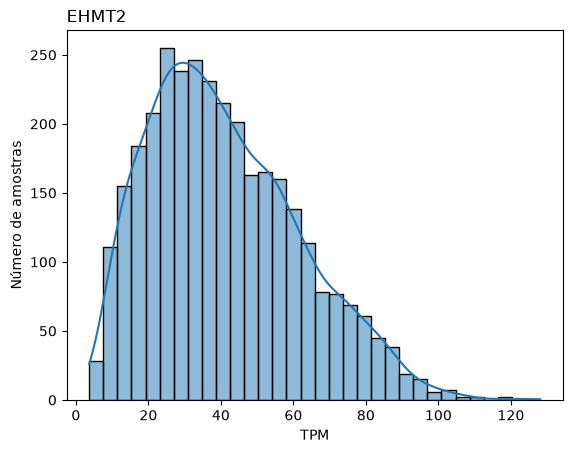

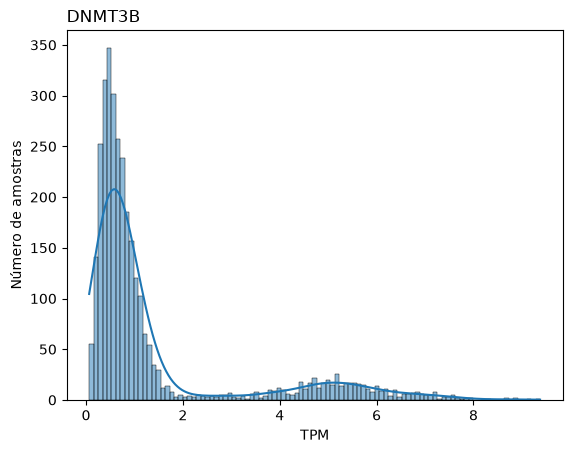

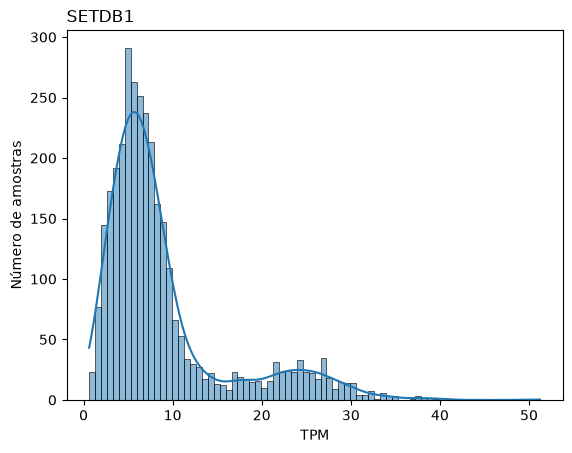

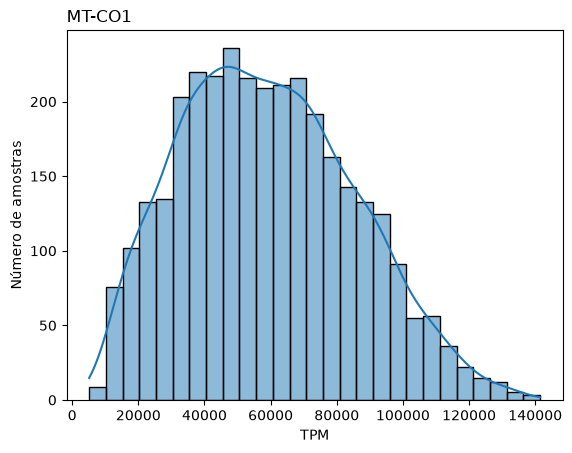

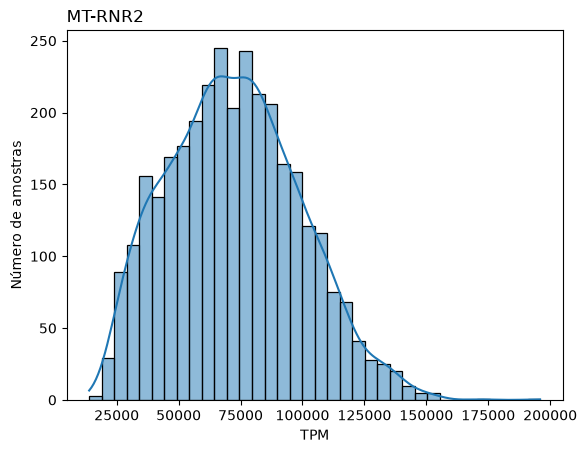

In [19]:
# Histogram of the TPM of each selected gene
for gene in L1_REGULATORS_WITH_2_STEPS_FROM_MECP2 + MORE_EXPRESSED_GENES:
    tpm = expression.xs(gene, level="Description").iloc[0]
    sns.histplot(tpm, kde=True)
    plt.xlabel("TPM")
    plt.ylabel("Número de amostras")
    plt.title(gene, loc="left")
    plt.show()

Esses genes foram selecionados por conheciamento de dominio, L1 derivado de pesquisas em RETT e os MT-* por serem os genes que apresentaram maior variancia nas análises multivariadas.

In [20]:
# Variation summary (mean, std, variance, median, min, max) of each L1 regulator
l1 = genes[genes["Description"].isin(L1_REGULATORS)]

l1_variation = l1.groupby("Description")["TPM"].agg(["mean", "std", "var", "median", "min","max"])
l1_variation = l1_variation.sort_values("var", ascending=False)
pd.set_option("display.max_rows", None)
l1_variation

,mean,std,var,median,min,max
Description,,,,,,
HSP90AA1,699.556733,648.457224,420496.771741,586.258500,50.301900,11038.900000
PABPN1,166.528361,101.949531,10393.706926,140.165000,13.837100,626.100000
HNRNPA2B1,139.159864,88.162079,7772.552110,114.512000,12.541700,572.068000
MATR3,123.531390,74.001400,5476.207229,108.693000,8.347910,511.379000
HNRNPL,106.704864,60.047510,3605.703460,94.197950,9.803010,397.647000
NCL,110.932614,54.372767,2956.397842,99.932550,12.974200,365.579000
XRCC6,100.042270,52.229826,2727.954733,92.680150,10.167900,317.946000
TRIM28,69.347144,49.966039,2496.605043,54.293700,6.497580,326.587000
UPF3A,51.561666,38.149064,1455.351081,38.059350,4.549770,196.008000


Tabela para ver o quanto os valores dos reguladores variam entre si

## Variáveis por amostra

In [21]:
# Per-sample features: detected genes, mitochondrial fraction and L1 panel statistics
sample_features = []
for region, expr in regions.items():
    tpm = expr.drop(columns=["Name", "Description"])
    gene_names = expr["Description"]
    l1_tpm = tpm[gene_names.isin(L1_REGULATORS)]
    sample_features.append(pd.DataFrame({
        "region": region.value,
        "genes_detected": (tpm > 0).sum(),
        "mito_fraction": tpm[gene_names.str.startswith("MT-")].sum() / tpm.sum(),
        "l1_mean": l1_tpm.mean(),
        "l1_median": l1_tpm.median(),
        "l1_std": l1_tpm.std(),
    }))

sample_features = pd.concat(sample_features)
sample_features.index.name = "sample"
sample_features["SUBJID"] = sample_features.index.str.split("-").str[:2].str.join("-")
sample_features["regions_per_donor"] = sample_features.groupby("SUBJID")["region"].transform("count")
sample_features.head()

,region,genes_detected,mito_fraction,l1_mean,l1_median,l1_std,SUBJID,regions_per_donor
sample,,,,,,,,
GTEX-1117F-0011-R4b-SM-GI4VM,amygdala,35046,0.740931,14.165109,4.11165,28.287962,GTEX-1117F,9
GTEX-111FC-0011-R4a-SM-GIN8K,amygdala,35142,0.587657,22.240392,4.95087,61.893634,GTEX-111FC,11
GTEX-117XS-0011-R4b-SM-GJ3PR,amygdala,35328,0.614051,21.408056,5.43052,59.581817,GTEX-117XS,13
GTEX-11DXY-0011-R4b-SM-GI4VR,amygdala,37243,0.524980,24.858480,7.14566,59.710646,GTEX-11DXY,11
GTEX-11DYG-0011-R4b-SM-GJ3RG,amygdala,32464,0.681308,12.833903,3.34781,30.325916,GTEX-11DYG,10


In [22]:
# Descriptive statistics, skewness and kurtosis of the per-sample features
numeric_features = ["genes_detected", "mito_fraction", "l1_mean", "l1_median", "l1_std", "regions_per_donor"]
pd.concat([sample_features[numeric_features].describe(), sample_features[numeric_features].agg(["skew", "kurt"])])

,genes_detected,mito_fraction,l1_mean,l1_median,l1_std,regions_per_donor
count,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000
mean,36176.974026,0.592753,26.083219,6.653384,75.150758,9.651206
std,2625.751159,0.151567,13.644341,3.107452,62.566485,2.578106
min,24483.000000,0.106651,3.036241,0.667770,6.108473,1.000000
25%,34704.000000,0.491007,16.850203,4.416120,42.614337,8.000000
50%,36344.500000,0.593865,23.812030,6.181195,65.739133,10.000000
75%,37896.000000,0.702225,32.819737,8.422557,89.926798,12.000000
max,51854.000000,0.935189,140.888908,21.483600,1065.398804,13.000000
skew,-0.294930,-0.149304,1.710981,0.774291,6.364895,-1.024492
kurt,1.169014,-0.544470,7.438123,0.611537,69.214402,0.608591


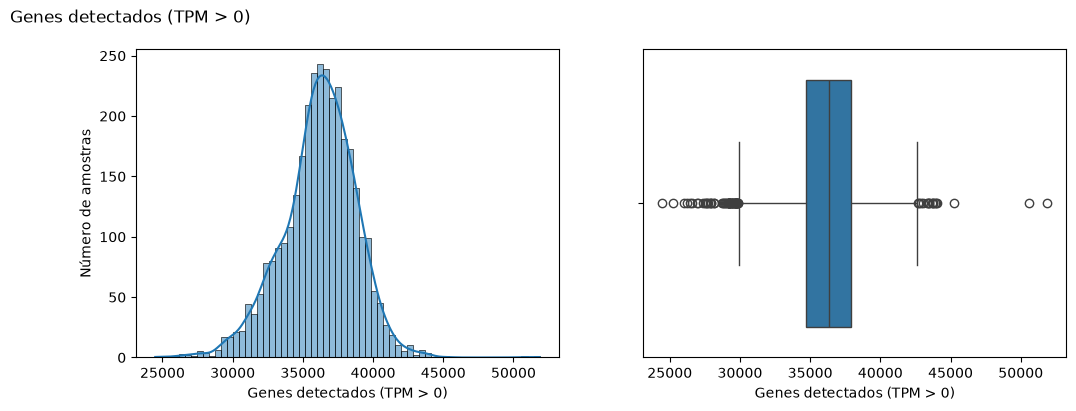

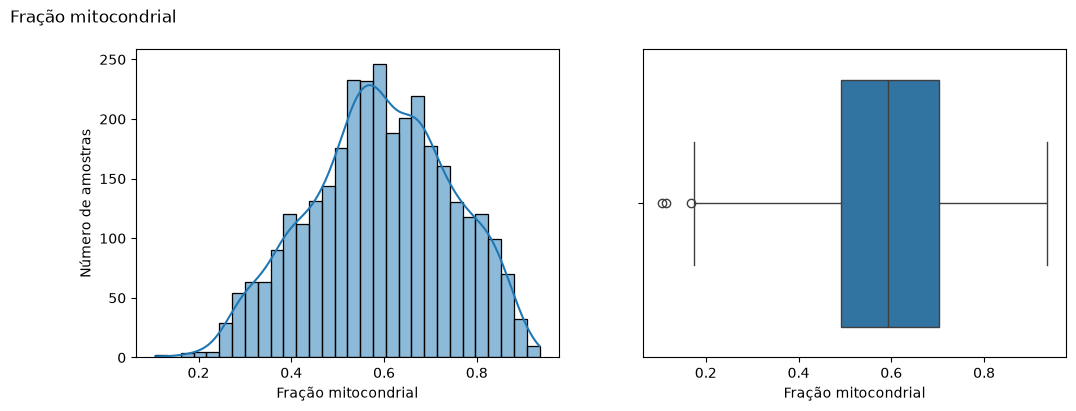

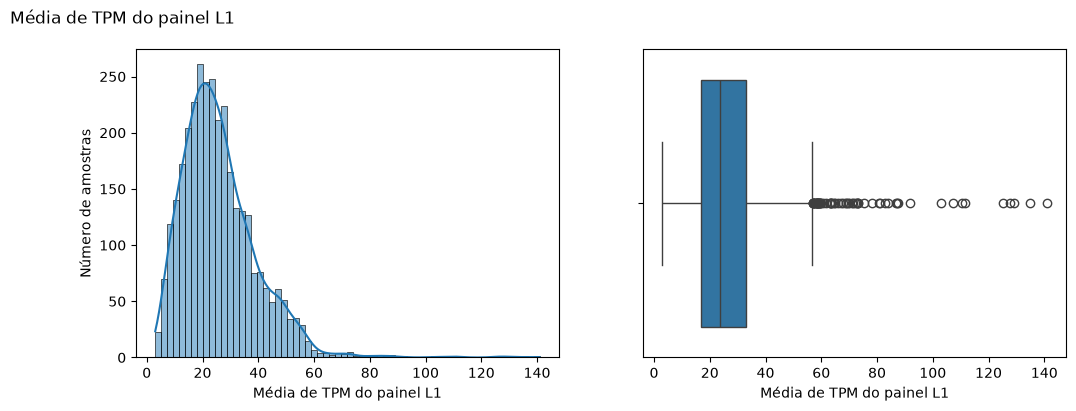

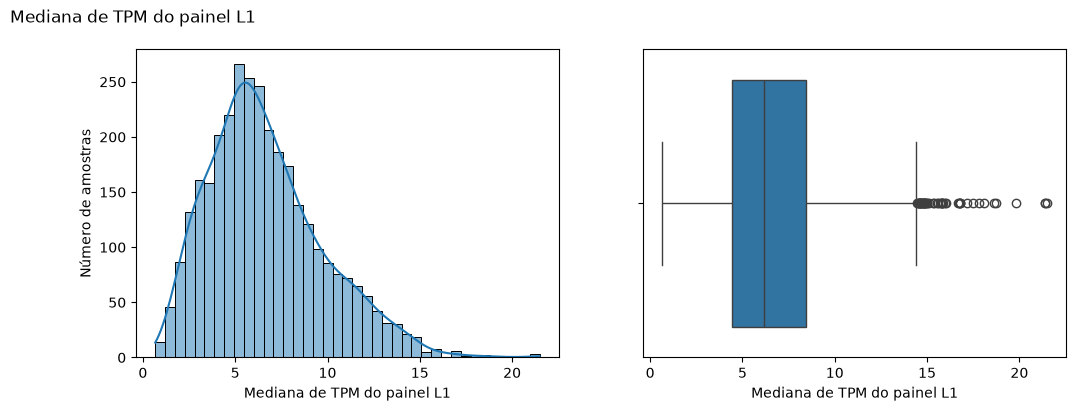

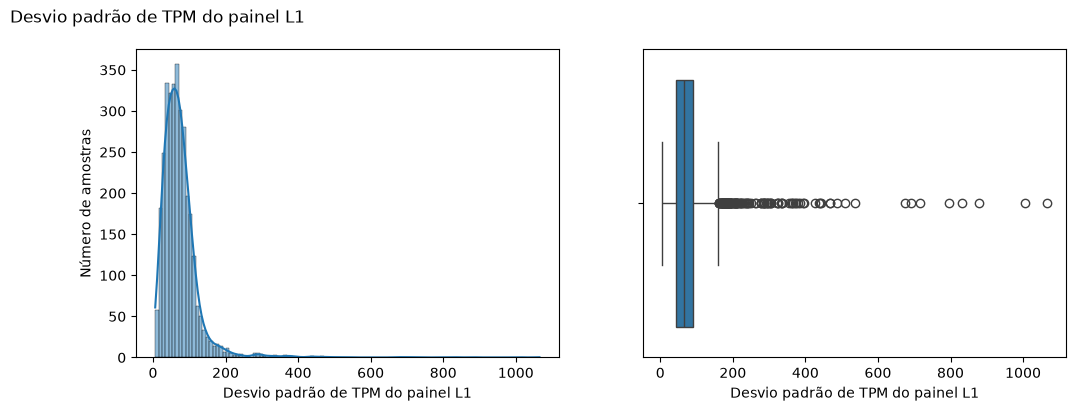

In [23]:
# Histogram and box plot of each per-sample feature
feature_labels = {
    "genes_detected": "Genes detectados (TPM > 0)",
    "mito_fraction": "Fração mitocondrial",
    "l1_mean": "Média de TPM do painel L1",
    "l1_median": "Mediana de TPM do painel L1",
    "l1_std": "Desvio padrão de TPM do painel L1",
}

for feature, label in feature_labels.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(sample_features[feature], kde=True, ax=axes[0])
    sns.boxplot(x=sample_features[feature], orient="h", ax=axes[1])
    axes[0].set_xlabel(label)
    axes[0].set_ylabel("Número de amostras")
    axes[1].set_xlabel(label)
    fig.suptitle(label, x=0.02, ha="left")
    plt.show()

As variáveis ligadas ao painel de reguladores de L1 têm assimetria positiva: `l1_mean` (skew 1,71), `l1_median` (0,77) e principalmente `l1_std` (6,37). Já `genes_detected` (-0,30) e `mito_fraction` (-0,15) são praticamente simétricas.

A média de `l1_mean` (26,1 TPM) fica bem acima da mediana do painel (6,7 TPM), o que mostra que poucos genes muito expressos puxam a média para cima. O `l1_std` tem curtose de 69, ou seja, há poucas amostras com valores muito extremos, que aparecem como outliers no boxplot.

Por isso as variáveis do painel de L1 precisam de uma transformação para ficarem mais simétricas, por exemplo log, antes de serem usadas em modelos que desempenham melhor com esse tipo de distribuição.

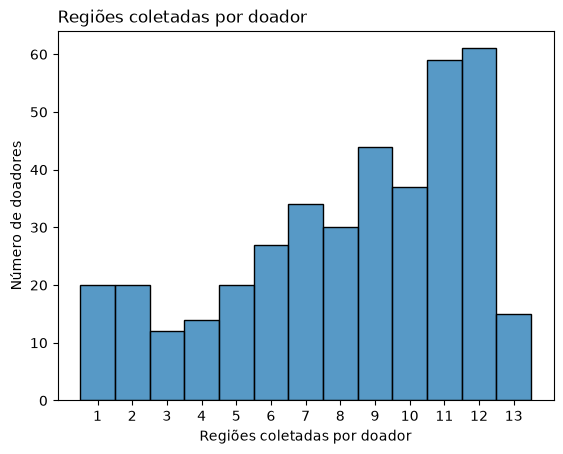

In [24]:
# Number of brain regions collected per donor
donors = sample_features.drop_duplicates("SUBJID")
sns.histplot(donors["regions_per_donor"], discrete=True)
plt.xticks(range(1, 14))
plt.xlabel("Regiões coletadas por doador")
plt.ylabel("Número de doadores")
plt.title("Regiões coletadas por doador", loc="left")
plt.show()

Aqui vemos que poucos doadores aparecem em apenas uma região: são 20 dos 393 doadores (5%). A maior parte doou amostras de 9 ou mais regiões, e 15 doadores têm as 13 regiões. Assim, é possível comparar como os genes variam em diferentes conjuntos anatômicos dentro da mesma pessoa.